# 09 · Detectives de RL: ocho programas que funcionan… y están equivocados

Este taller es material añadido al grupo de lectura, no un capítulo 9 del libro. Aquí encontrarás funciones pequeñas que ejecutan sin errores de sintaxis, pero calculan algo distinto de lo que deberían.

**Tu tarea:** formular una hipótesis, localizar el fallo, modificar la función y aportar una explicación. Las pruebas no son el ejercicio entero: una reparación que puedes justificar vale más que cambiar líneas hasta ver todo verde.

**Punto de partida:** los ocho retos vienen sin resolver. Al ejecutar todo, aparecerán comprobaciones fallidas y un panel con 0/8 retos resueltos. Es el resultado previsto del taller. Las excepciones de las pruebas se capturan para que puedas continuar; no hay que instalar nada además de NumPy y Matplotlib.

| Reto | Tema | Preparación recomendada |
|---|---|---|
| R1 | Retorno y descuento | [00](../cuadernos/00_preparacion.ipynb), [1](../cuadernos/01_introduccion.ipynb) |
| R2 | Valores terminales | [2](../cuadernos/02_valores.ipynb) |
| R3 | Ejes de una política softmax | [00](../cuadernos/00_preparacion.ipynb), [3](../cuadernos/03_politicas.ipynb) |
| R4 | Crédito entre episodios con GAE | [3](../cuadernos/03_politicas.ipynb) |
| R5 | Baseline de RLOO | [6](../cuadernos/06_llms.ipynb) |
| R6 | Gradiente del objetivo con KL | [3](../cuadernos/03_politicas.ipynb), [6](../cuadernos/06_llms.ipynb) |
| R7 | Fuga de información en validación | [00](../cuadernos/00_preparacion.ipynb), [7](../cuadernos/07_otros_temas.ipynb) |
| R8 | Réplicas que no aportan evidencia nueva | [8](../cuadernos/08_agradecimientos.ipynb) |

Puedes resolver R1–R3 en una sesión, R4–R6 en otra y cerrar con R7–R8. No hace falta terminarlo de una vez.

## Cómo trabajar sin adelantarte la solución

1. Lee el contrato de la función y predice qué ejemplo revelará el fallo.
2. Ejecuta el caso y sus pruebas. Una comprobación que pasa no implica que la función sea correcta.
3. Corrige **solo la función del reto**. Mantén su nombre, argumentos y valor devuelto.
4. Reejecuta la celda de la función y la de sus pruebas.
5. Si te bloqueas, abre primero la pista y después la solución.
6. Termina con el panel general y escribe una limitación de las pruebas.

Las soluciones son bloques de texto desplegables; no se ejecutan al pulsar Run All. Puedes copiarlas en la celda de la función cuando quieras contrastar tu propuesta. El código del taller vive dentro del notebook y no modifica los algoritmos de otros capítulos.

## Preparar el banco de pruebas

Las comprobaciones se basan en casos calculables a mano, identidades y propiedades: normalización, independencia del conjunto de validación, dirección de mejora y separación de episodios. No comparan el texto de tu solución con una respuesta prefijada.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})

BATERIA = {}
REGISTRO = {}
HIPOTESIS = {f"R{i}": "" for i in range(1, 9)}  # Anota aquí tus predicciones.

def iguales(actual, esperado, tolerancia=1e-10):
    actual, esperado = np.asarray(actual), np.asarray(esperado)
    assert actual.shape == esperado.shape, f"Forma {actual.shape}; se esperaba {esperado.shape}"
    try:
        np.testing.assert_allclose(actual, esperado, atol=tolerancia, rtol=0)
    except AssertionError:
        raise AssertionError(f"Obtenido {actual}; esperado {esperado}") from None

def exigir(condicion, mensaje):
    assert bool(condicion), mensaje

def debe_rechazar(funcion):
    try:
        funcion()
    except ValueError:
        return
    raise AssertionError("Se esperaba ValueError para esta entrada no admitida")

def probar(reto, pruebas):
    resultados = []
    for descripcion, prueba in pruebas:
        try:
            prueba()
            resultados.append((descripcion, True, ""))
            print("  PASA  ", descripcion)
        except Exception as error:
            detalle = " ".join(str(error).split())[:180]
            resultados.append((descripcion, False, f"{type(error).__name__}: {detalle}"))
            print("  FALLA ", descripcion, "→", resultados[-1][2])
    pasan = sum(ok for _, ok, _ in resultados)
    REGISTRO[reto] = {"pasan": pasan, "total": len(pruebas),
                     "resuelto": pasan == len(pruebas), "detalle": resultados}
    print(f"{reto}: {pasan}/{len(pruebas)} comprobaciones; "
          + ("resuelto en esta batería" if pasan == len(pruebas) else "por corregir"))


## R1 · El retorno no coincide con nuestra cuenta

**Contrato:** calcula $G_0=\sum_{t=0}^{T-1}\gamma^t r_t$ para una secuencia finita. El premio del primer instante no se descuenta. Se admite una secuencia vacía, cuyo retorno es cero, y gamma entre cero y uno.

Una simulación parece dar valores razonables, pero falla al comparar políticas con recompensas inmediatas. Predice qué debería pasar cuando gamma es cero. No arregles la prueba eligiendo gamma=1: ese valor puede ocultar el problema.


In [2]:
def retorno_reto(recompensas, gamma):
    recompensas = np.asarray(recompensas, dtype=float)
    potencias = gamma ** np.arange(1, len(recompensas)+1)
    return float(potencias @ recompensas)

print("La función dice:", retorno_reto([1, 0, 2], 0.5))
print("Tu cálculo a mano debería explicar cada exponente.")


La función dice: 0.75
Tu cálculo a mano debería explicar cada exponente.


In [3]:
BATERIA["R1"] = [
    ("El premio inmediato conserva su valor", lambda: iguales(retorno_reto([5], 0.3), 5)),
    ("Gamma cero conserva solo el primer premio", lambda: iguales(retorno_reto([4, 9], 0), 4)),
    ("Trayectoria con premio retrasado", lambda: iguales(retorno_reto([1, 0, 2], 0.5), 1.5)),
    ("Sin descuento se suman los premios", lambda: iguales(retorno_reto([1, 0, 2], 1), 3)),
    ("La trayectoria vacía vale cero", lambda: iguales(retorno_reto([], 0.9), 0)),
]
probar("R1", BATERIA["R1"])


  FALLA  El premio inmediato conserva su valor → AssertionError: Obtenido 1.5; esperado 5
  FALLA  Gamma cero conserva solo el primer premio → AssertionError: Obtenido 0.0; esperado 4
  FALLA  Trayectoria con premio retrasado → AssertionError: Obtenido 0.75; esperado 1.5
  PASA   Sin descuento se suman los premios
  PASA   La trayectoria vacía vale cero
R1: 2/5 comprobaciones; por corregir


La siguiente figura cambia después de editar la función. Compara recibir 3 en el instante 4 con el cálculo analítico. Si ambas curvas coinciden tras tu reparación, explica por qué la discrepancia original era mayor para ciertos descuentos.


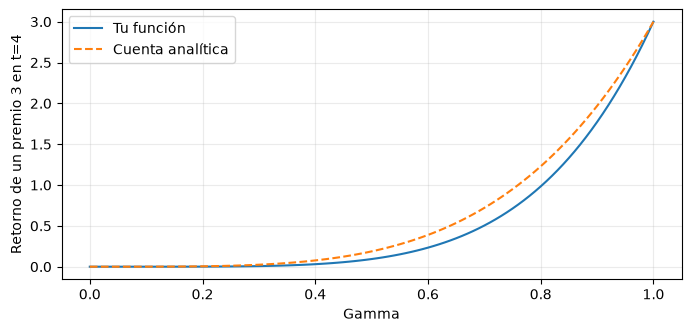

In [4]:
gammas = np.linspace(0, 1, 101)
observado = [retorno_reto([0, 0, 0, 0, 3], g) for g in gammas]
plt.plot(gammas, observado, label="Tu función")
plt.plot(gammas, 3*gammas**4, "--", label="Cuenta analítica")
plt.xlabel("Gamma")
plt.ylabel("Retorno de un premio 3 en t=4")
plt.legend()
plt.show()


<details>
<summary>Pista R1</summary>

Mira el primer y el último elemento del array de exponentes. En una secuencia de longitud cinco, los instantes son 0, 1, 2, 3 y 4.

</details>

<details>
<summary>Solución R1 y explicación</summary>

```python
def retorno_reto(recompensas, gamma):
    recompensas = np.asarray(recompensas, dtype=float)
    potencias = gamma ** np.arange(len(recompensas))
    return float(potencias @ recompensas)
```

El código original desplazaba todos los premios un instante hacia el futuro. Con gamma=1 el error queda oculto. Que una prueba pase en un caso límite no certifica la indexación general.

</details>

## R2 · Una meta que acumula premios después de terminar

**Contrato:** devuelve el objetivo TD $r+\gamma V(s')$ si la tarea continúa y solo r si la transición llega a un terminal real. Recibe un valor siguiente finito, aunque su casilla pueda contener una estimación residual que deba ignorarse al terminar.

El agente aprende un valor enorme para llegar a una meta. El evaluador sospecha que está contando consecuencias que ya no existen. Calcula a mano una transición terminal de premio 1 cuyo valor siguiente almacenado es 100.


In [5]:
def objetivo_td_reto(recompensa, gamma, valor_siguiente, terminado):
    return recompensa + gamma*valor_siguiente

print("Objetivo al llegar a una meta:", objetivo_td_reto(1, 0.9, 100, True))


Objetivo al llegar a una meta: 91.0


In [6]:
BATERIA["R2"] = [
    ("Un terminal no recibe bootstrap", lambda: iguales(objetivo_td_reto(1, 0.9, 100, True), 1)),
    ("Tampoco se resta un valor terminal residual negativo",
     lambda: iguales(objetivo_td_reto(-2, 0.9, -30, True), -2)),
    ("Una transición normal sí usa el valor siguiente",
     lambda: iguales(objetivo_td_reto(1, 0.9, 4, False), 4.6)),
    ("Gamma cero ignora el futuro", lambda: iguales(objetivo_td_reto(2, 0, 20, False), 2)),
]
probar("R2", BATERIA["R2"])


  FALLA  Un terminal no recibe bootstrap → AssertionError: Obtenido 91.0; esperado 1
  FALLA  Tampoco se resta un valor terminal residual negativo → AssertionError: Obtenido -29.0; esperado -2
  PASA   Una transición normal sí usa el valor siguiente
  PASA   Gamma cero ignora el futuro
R2: 2/4 comprobaciones; por corregir


<details>
<summary>Pista R2</summary>

El argumento terminado no aparece en el cálculo. Una entrada sin uso puede ser una pista de que el contrato se ha perdido.

</details>

<details>
<summary>Solución R2 y explicación</summary>

```python
def objetivo_td_reto(recompensa, gamma, valor_siguiente, terminado):
    if terminado:
        return float(recompensa)
    return recompensa + gamma*valor_siguiente
```

El valor del estado terminal es cero para la continuación de este episodio, aunque entrar en él dé recompensa. Un corte artificial de la recogida de datos no siempre equivale a un terminal del problema: para una tarea que continúa, puede seguir correspondiendo bootstrap. Aquí el argumento significa terminal real, no cualquier motivo para detener el bucle.

</details>

## R3 · Cambiar otro ejemplo del lote cambia mi política

**Contrato:** recibe logits con forma lote × acciones y devuelve una distribución sobre acciones **por fila**, con la misma forma. Los logits son finitos. El resultado de una fila no debe depender de los valores de otra.

En producción, la política parece variar cuando cambia el tamaño del lote. Prueba a sumar cien a todos los logits de una sola fila. Esa fila debería conservar su distribución, y las demás también.


In [7]:
def softmax_lote_reto(logits):
    logits = np.asarray(logits, dtype=float)
    e = np.exp(logits-logits.max())
    return e/e.sum()

lote = np.array([[0.0, 1.0, 2.0], [2.0, 1.0, 0.0]])
print("Probabilidades:\n", softmax_lote_reto(lote))
print("Sumas por fila:", softmax_lote_reto(lote).sum(axis=1))


Probabilidades:
 [[0.04502 0.12236 0.33262]
 [0.33262 0.12236 0.04502]]
Sumas por fila: [0.5 0.5]


In [8]:
def fila_independiente():
    original = np.array([[0.0, 1.0, 2.0], [2.0, 1.0, 0.0]])
    cambiado = original.copy()
    cambiado[1] += 100
    iguales(softmax_lote_reto(original), softmax_lote_reto(cambiado))

BATERIA["R3"] = [
    ("Cada fila suma uno", lambda: iguales(softmax_lote_reto(lote).sum(axis=1), [1, 1])),
    ("Una fila uniforme produce tercios",
     lambda: iguales(softmax_lote_reto(np.zeros((2, 3))), np.ones((2, 3))/3)),
    ("Cambiar el desplazamiento de otra fila no afecta a la política", fila_independiente),
    ("Logits grandes siguen dando distribuciones finitas",
     lambda: iguales(softmax_lote_reto(np.array([[1000, 1000], [-1000, -1000]])),
                     np.full((2, 2), 0.5))),
]
probar("R3", BATERIA["R3"])


  FALLA  Cada fila suma uno → AssertionError: Obtenido [0.5 0.5]; esperado [1 1]
  FALLA  Una fila uniforme produce tercios → AssertionError: Obtenido [[0.16667 0.16667 0.16667] [0.16667 0.16667 0.16667]]; esperado [[0.33333 0.33333 0.33333] [0.33333 0.33333 0.33333]]
  FALLA  Cambiar el desplazamiento de otra fila no afecta a la política → AssertionError: Obtenido [[0.04502 0.12236 0.33262] [0.33262 0.12236 0.04502]]; esperado [[0. 0. 0. ] [0.66524 0.24473 0.09003]]
  FALLA  Logits grandes siguen dando distribuciones finitas → AssertionError: Obtenido [[0.5 0.5] [0. 0. ]]; esperado [[0.5 0.5] [0.5 0.5]]
R3: 0/4 comprobaciones; por corregir


<details>
<summary>Pista R3</summary>

Las operaciones max y sum necesitan saber qué eje contiene las acciones. Conservar ese eje como dimensión de tamaño uno facilita el broadcasting.

</details>

<details>
<summary>Solución R3 y explicación</summary>

```python
def softmax_lote_reto(logits):
    logits = np.asarray(logits, dtype=float)
    e = np.exp(logits-logits.max(axis=1, keepdims=True))
    return e/e.sum(axis=1, keepdims=True)
```

El original normalizaba el lote entero como una única distribución. El máximo también debe calcularse por fila: restar un máximo global puede hacer que todas las exponenciales de una fila muy desplazada se redondeen a cero. No basta con comprobar que la suma de todos los elementos sea uno.

</details>

## R4 · La recompensa de mañana mejora el episodio de ayer

**Contrato:** calcula GAE para una secuencia que puede contener varios episodios concatenados. Hay T recompensas, T indicadores terminales y T+1 valores. Cuando terminado[t] es verdadero, no debe propagarse información desde t+1 hacia t.

Usamos la convención

$$\delta_t=r_t+\gamma(1-d_t)V_{t+1}-V_t,\qquad
A_t=\delta_t+\gamma\lambda(1-d_t)A_{t+1}.$$

El delta parece correcto. Sin embargo, un episodio de una sola acción recibe más ventaja si otro episodio del mismo lote obtuvo mucha recompensa. Antes de mirar el código, predice las ventajas de dos episodios independientes con premios 1 y 100 y valores cero.


In [9]:
def gae_reto(recompensas, valores, terminado, gamma=0.9, lam=1.0):
    ventajas = np.zeros(len(recompensas))
    siguiente = 0.0
    for t in reversed(range(len(recompensas))):
        delta = recompensas[t] + gamma*(not terminado[t])*valores[t+1] - valores[t]
        siguiente = delta + gamma*lam*siguiente
        ventajas[t] = siguiente
    return ventajas

print("Dos episodios de un paso:",
      gae_reto([1, 100], [0, 0, 0], [True, True]))


Dos episodios de un paso: [ 91. 100.]


In [10]:
BATERIA["R4"] = [
    ("Los episodios no comparten crédito",
     lambda: iguales(gae_reto([1, 100], [0, 0, 0], [True, True]), [1, 100])),
    ("Un episodio de dos pasos sí propaga su propio crédito",
     lambda: iguales(gae_reto([0, 1], [0.2, 0.4, 0], [False, True]), [0.7, 0.6])),
    ("Lambda cero usa solo errores TD",
     lambda: iguales(gae_reto([1, 100], [0, 0, 0], [True, True], lam=0), [1, 100])),
    ("Un fragmento no terminal conserva bootstrap",
     lambda: iguales(gae_reto([0], [0.2, 0.5], [False]), [0.25])),
]
probar("R4", BATERIA["R4"])


  FALLA  Los episodios no comparten crédito → AssertionError: Obtenido [ 91. 100.]; esperado [ 1 100]
  PASA   Un episodio de dos pasos sí propaga su propio crédito
  PASA   Lambda cero usa solo errores TD
  PASA   Un fragmento no terminal conserva bootstrap
R4: 3/4 comprobaciones; por corregir


<details>
<summary>Pista R4</summary>

Hay dos caminos por los que entra el futuro: el valor siguiente dentro del delta y la ventaja acumulada de la recursión.

</details>

<details>
<summary>Solución R4 y explicación</summary>

```python
def gae_reto(recompensas, valores, terminado, gamma=0.9, lam=1.0):
    ventajas = np.zeros(len(recompensas))
    siguiente = 0.0
    for t in reversed(range(len(recompensas))):
        mascara = 1.0-float(terminado[t])
        delta = recompensas[t] + gamma*mascara*valores[t+1] - valores[t]
        siguiente = delta + gamma*lam*mascara*siguiente
        ventajas[t] = siguiente
    return ventajas
```

Enmascarar solo el bootstrap no corta la recursión de ventajas. Con lambda=0 el fallo se esconde. La prueba de episodios concatenados comprueba una frontera que una trayectoria individual no puede revelar.

</details>

## R5 · El baseline reduce también el gradiente esperado

**Contrato:** para K>1 recompensas de respuestas independientes del mismo prompt, devuelve ventajas RLOO. La referencia de cada muestra es la media de las otras K−1 recompensas. Para K=1 debe rechazar la entrada mediante ValueError: no existen otras respuestas.

El entrenamiento parece avanzar más despacio al reducir el grupo. No queremos arreglarlo subiendo arbitrariamente la tasa: primero comprobaremos qué gradiente estima.


In [11]:
def ventajas_rloo_reto(recompensas):
    r = np.asarray(recompensas, dtype=float)
    return r-r.mean()

print("Ventajas para premios [1, 3]:", ventajas_rloo_reto([1, 3]))


Ventajas para premios [1, 3]: [-1.  1.]


La prueba más informativa enumera todas las parejas posibles de acciones. La política es (0.25, 0.75) y las recompensas, (0, 2). El objetivo exacto tiene gradiente (−0.375, 0.375) respecto a logits. Enumerar elimina el ruido de muestreo: una diferencia no puede justificarse como mala suerte.


In [12]:
def esperanza_gradiente_rloo():
    p = np.array([0.25, 0.75])
    premio = np.array([0.0, 2.0])
    gradiente = np.zeros(2)
    for i in range(2):
        for j in range(2):
            acciones = np.array([i, j])
            score = np.eye(2)[acciones]-p
            ventajas = ventajas_rloo_reto(premio[acciones])
            gradiente += p[i]*p[j]*np.mean(ventajas[:, None]*score, axis=0)
    return gradiente

BATERIA["R5"] = [
    ("Con dos respuestas, cada una usa a la otra",
     lambda: iguales(ventajas_rloo_reto([1, 3]), [-2, 2])),
    ("Premios iguales dan ventajas cero",
     lambda: iguales(ventajas_rloo_reto([4, 4, 4]), [0, 0, 0])),
    ("Un desplazamiento común no cambia las ventajas",
     lambda: iguales(ventajas_rloo_reto([11, 13]), ventajas_rloo_reto([1, 3]))),
    ("La esperanza coincide con el gradiente exacto",
     lambda: iguales(esperanza_gradiente_rloo(), [-0.375, 0.375])),
    ("Un grupo de una respuesta no define RLOO",
     lambda: debe_rechazar(lambda: ventajas_rloo_reto([3]))),
]
probar("R5", BATERIA["R5"])


  FALLA  Con dos respuestas, cada una usa a la otra → AssertionError: Obtenido [-1. 1.]; esperado [-2 2]
  PASA   Premios iguales dan ventajas cero
  PASA   Un desplazamiento común no cambia las ventajas
  FALLA  La esperanza coincide con el gradiente exacto → AssertionError: Obtenido [-0.1875 0.1875]; esperado [-0.375 0.375]
  FALLA  Un grupo de una respuesta no define RLOO → AssertionError: Se esperaba ValueError para esta entrada no admitida
R5: 2/5 comprobaciones; por corregir


<details>
<summary>Pista R5</summary>

Si la propia recompensa entra en su baseline, el centrado depende de la misma acción que multiplica. Mira tanto el numerador como el denominador.

</details>

<details>
<summary>Solución R5 y explicación</summary>

```python
def ventajas_rloo_reto(recompensas):
    r = np.asarray(recompensas, dtype=float)
    if len(r) < 2:
        raise ValueError("RLOO requiere al menos dos respuestas")
    baseline = (r.sum()-r)/(len(r)-1)
    return r-baseline
```

Restar la media del grupo completo sin corrección multiplica la esperanza de este estimador por (K−1)/K. En el grupo de dos respuestas aparece exactamente la mitad del gradiente. Que las ventajas sumen cero no basta para identificar el estimador correcto.

</details>

## R6 · Penalizar la distancia hace que la política se aleje

**Contrato:** devuelve el gradiente, respecto a logits, del objetivo que queremos **maximizar**:

$$J(\theta)=p_\theta^\top r-\beta\,\mathrm{KL}(p_\theta\|p_{\rm ref}).$$

La referencia tiene probabilidades estrictamente positivas y beta es no negativo. El código usa softmax estable. Con recompensa cero, una actualización pequeña de ascenso debería acercarnos a la referencia si aún no estamos en ella.

La función del objetivo que aparece a continuación es el evaluador. Tu intervención está en gradiente_kl_reto, no en cambiar qué significa J.


In [13]:
def softmax_vector(theta):
    e = np.exp(np.asarray(theta, dtype=float)-np.max(theta))
    return e/e.sum()

def objetivo_kl(theta, recompensa, referencia, beta):
    p = softmax_vector(theta)
    return float(p@recompensa-beta*np.sum(p*np.log(p/referencia)))

def gradiente_kl_reto(theta, recompensa, referencia, beta):
    p = softmax_vector(theta)
    utilidad = recompensa + beta*(np.log(p/referencia)+1)
    return p*(utilidad-p@utilidad)

ref = np.array([0.5, 0.5])
theta_inicial = np.log([0.9, 0.1])
print("Gradiente con recompensa cero:",
      gradiente_kl_reto(theta_inicial, np.zeros(2), ref, 1.0))


Gradiente con recompensa cero: [ 0.19775 -0.19775]


In [14]:
def comprobar_derivada_kl():
    theta = np.array([0.3, -0.4, 0.1])
    premio = np.array([1.0, -0.2, 0.5])
    referencia = np.array([0.5, 0.2, 0.3])
    h = 1e-5
    numerico = np.array([
        (objetivo_kl(theta+h*np.eye(3)[i], premio, referencia, 0.7)
         - objetivo_kl(theta-h*np.eye(3)[i], premio, referencia, 0.7))/(2*h)
        for i in range(3)
    ])
    iguales(gradiente_kl_reto(theta, premio, referencia, 0.7), numerico, tolerancia=1e-8)

def comprobar_direccion_kl():
    theta = np.log([0.9, 0.1])
    r, ref = np.zeros(2), np.array([0.5, 0.5])
    siguiente = theta+0.01*gradiente_kl_reto(theta, r, ref, 1.0)
    exigir(objetivo_kl(siguiente, r, ref, 1) > objetivo_kl(theta, r, ref, 1),
           "El paso de ascenso empeora J cuando solo existe la penalización")

BATERIA["R6"] = [
    ("El gradiente coincide con diferencias finitas", comprobar_derivada_kl),
    ("Un paso pequeño mejora el objetivo de solo KL", comprobar_direccion_kl),
    ("En la referencia y sin recompensa el gradiente es cero",
     lambda: iguales(gradiente_kl_reto(np.log(ref), np.zeros(2), ref, 1), [0, 0])),
    ("Con beta cero queda el gradiente de recompensa",
     lambda: iguales(gradiente_kl_reto(np.zeros(2), np.array([0, 1]), ref, 0), [-0.25, 0.25])),
]
probar("R6", BATERIA["R6"])


  FALLA  El gradiente coincide con diferencias finitas → AssertionError: Obtenido [ 0.14027 -0.15525 0.01497]; esperado [ 0.23478 -0.17326 -0.06152]
  FALLA  Un paso pequeño mejora el objetivo de solo KL → AssertionError: El paso de ascenso empeora J cuando solo existe la penalización
  PASA   En la referencia y sin recompensa el gradiente es cero
  PASA   Con beta cero queda el gradiente de recompensa
R6: 2/4 comprobaciones; por corregir


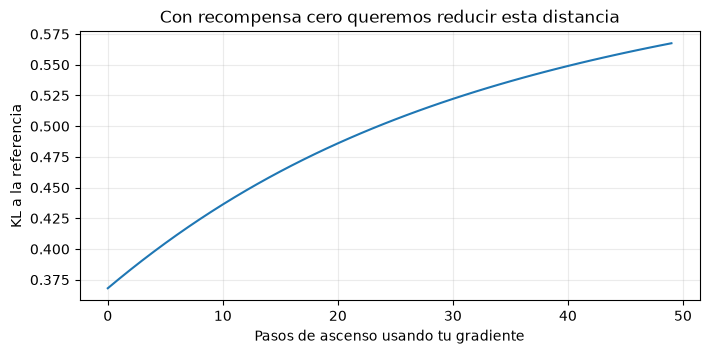

In [15]:
theta = theta_inicial.copy()
distancias = []
for _ in range(50):
    p = softmax_vector(theta)
    distancias.append(np.sum(p*np.log(p/ref)))
    theta += 0.1*gradiente_kl_reto(theta, np.zeros(2), ref, 1.0)
plt.plot(distancias)
plt.xlabel("Pasos de ascenso usando tu gradiente")
plt.ylabel("KL a la referencia")
plt.title("Con recompensa cero queremos reducir esta distancia")
plt.show()


<details>
<summary>Pista R6</summary>

No cambies ascenso por descenso: J incluye una recompensa que queremos maximizar. Revisa con qué signo entra la derivada de la penalización.

</details>

<details>
<summary>Solución R6 y explicación</summary>

```python
def gradiente_kl_reto(theta, recompensa, referencia, beta):
    p = softmax_vector(theta)
    utilidad = recompensa - beta*(np.log(p/referencia)+1)
    return p*(utilidad-p@utilidad)
```

El código original calculaba el gradiente de recompensa más KL. Premiar alejarse puede producir curvas suaves y valores finitos: ninguna de esas dos cosas garantiza que optimicemos el objetivo deseado.

</details>

## R7 · Un dato de validación modifica el entrenamiento

**Contrato:** centra cada característica restando la media estimada **solo con entrenamiento**. Aplica esa misma transformación tanto a entrenamiento como a validación. Devuelve dos arrays nuevos con las formas originales y conserva las entradas.

Los datos de validación deberían servir para evaluar o seleccionar, no para ajustar esta transformación. Si cambiamos sus valores y con ello cambia la representación de entrenamiento, estamos utilizando información que el contrato reserva.

No todo uso de datos sin etiquetas es siempre incorrecto: existen diseños transductivos. Este reto exige explícitamente un procedimiento inductivo que ajusta el preprocesamiento solo en entrenamiento.


In [16]:
def centrar_reto(entrenamiento, validacion):
    media = np.concatenate([entrenamiento, validacion], axis=0).mean(axis=0)
    return entrenamiento-media, validacion-media

train = np.array([[0.0], [2.0]])
valid = np.array([[100.0]])
print("Entrenamiento centrado:", centrar_reto(train, valid)[0].ravel())
print("Validación centrada:", centrar_reto(train, valid)[1].ravel())


Entrenamiento centrado: [-34. -32.]
Validación centrada: [66.]


In [17]:
def validacion_no_entrena():
    train = np.array([[0.0], [2.0]])
    primero = centrar_reto(train, np.array([[100.0]]))[0]
    segundo = centrar_reto(train, np.array([[10000.0]]))[0]
    iguales(primero, segundo)

def entradas_intactas():
    train = np.array([[0.0, 10.0], [2.0, 14.0], [4.0, 18.0]])
    valid = np.array([[100.0, 200.0]])
    copia_train, copia_valid = train.copy(), valid.copy()
    salida_train, salida_valid = centrar_reto(train, valid)
    iguales(train, copia_train)
    iguales(valid, copia_valid)
    exigir(not np.shares_memory(salida_train, train), "La salida comparte memoria con entrenamiento")
    exigir(not np.shares_memory(salida_valid, valid), "La salida comparte memoria con validación")

BATERIA["R7"] = [
    ("La media del entrenamiento transformado es cero",
     lambda: iguales(centrar_reto(train, valid)[0].mean(axis=0), [0])),
    ("Validación usa la media aprendida en entrenamiento",
     lambda: iguales(centrar_reto(train, valid)[1], [[99]])),
    ("Cambiar validación no modifica el ajuste", validacion_no_entrena),
    ("Las entradas se conservan y las salidas son nuevas", entradas_intactas),
]
probar("R7", BATERIA["R7"])


  FALLA  La media del entrenamiento transformado es cero → AssertionError: Obtenido [-33.]; esperado [0]
  FALLA  Validación usa la media aprendida en entrenamiento → AssertionError: Obtenido [[66.]]; esperado [[99]]
  FALLA  Cambiar validación no modifica el ajuste → AssertionError: Obtenido [[-34.] [-32.]]; esperado [[-3334.] [-3332.]]
  PASA   Las entradas se conservan y las salidas son nuevas
R7: 1/4 comprobaciones; por corregir


<details>
<summary>Pista R7</summary>

Separar los ejemplos antes de ajustar el modelo no basta si el preprocesamiento ya utilizó todos. La estadística aprendida también es parte del ajuste.

</details>

<details>
<summary>Solución R7 y explicación</summary>

```python
def centrar_reto(entrenamiento, validacion):
    media = entrenamiento.mean(axis=0)
    return entrenamiento-media, validacion-media
```

El contrato usa la misma media, aprendida en entrenamiento, en ambos conjuntos. Centrar cada conjunto con su propia media también incumpliría esa condición. Este ejemplo detecta una fuga concreta; no garantiza que no existan otras, como identidades repetidas o ventanas temporales solapadas.

</details>

## R8 · Veinte réplicas con una incertidumbre milagrosamente pequeña

**Contrato:** devuelve una media por réplica de n muestras normales estándar. Repetir la llamada con los mismos parámetros debe reproducir la salida, pero las réplicas de una llamada deben consumir muestras distintas.

La desviación entre ejecuciones sale cero. Parece un algoritmo extremadamente estable, hasta que observamos que todas las réplicas son copias.


In [18]:
def replicas_reto(seed, replicas=8, n=32):
    medias = []
    for _ in range(replicas):
        rng = np.random.default_rng(seed)
        medias.append(rng.normal(size=n).mean())
    return np.array(medias)

print("Medias por réplica:", replicas_reto(2026))


Medias por réplica: [0.00281 0.00281 0.00281 0.00281 0.00281 0.00281 0.00281 0.00281]


In [19]:
BATERIA["R8"] = [
    ("Repetir la llamada reproduce la salida",
     lambda: iguales(replicas_reto(2026), replicas_reto(2026))),
    ("Las réplicas no son copias exactas",
     lambda: exigir(np.unique(replicas_reto(2026)).size > 1, "Todas las medias son idénticas")),
    ("Se devuelve una media por réplica",
     lambda: exigir(replicas_reto(2026, replicas=5).shape == (5,), "Forma incorrecta")),
    ("Cambiar semilla modifica la realización",
     lambda: exigir(not np.array_equal(replicas_reto(2026), replicas_reto(2027)),
                    "La salida ignora la semilla")),
]
probar("R8", BATERIA["R8"])


  PASA   Repetir la llamada reproduce la salida
  FALLA  Las réplicas no son copias exactas → AssertionError: Todas las medias son idénticas
  PASA   Se devuelve una media por réplica
  PASA   Cambiar semilla modifica la realización
R8: 3/4 comprobaciones; por corregir


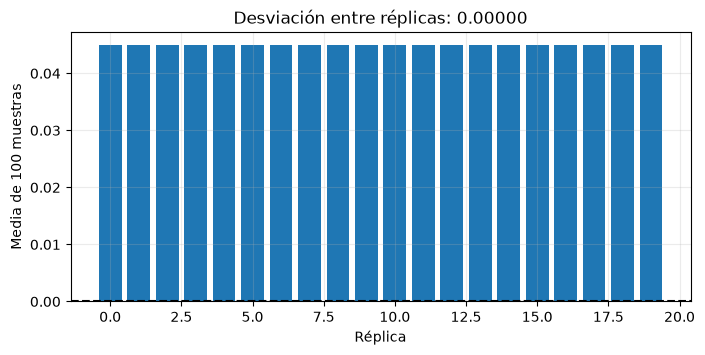

In [20]:
medias = replicas_reto(2026, replicas=20, n=100)
plt.bar(np.arange(len(medias)), medias)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Réplica")
plt.ylabel("Media de 100 muestras")
plt.title(f"Desviación entre réplicas: {medias.std(ddof=1):.5f}")
plt.show()


<details>
<summary>Pista R8</summary>

Fijar una semilla una vez permite reproducir un experimento completo. Reiniciar el generador en cada vuelta puede reiniciar también todos los datos.

</details>

<details>
<summary>Solución R8 y explicación</summary>

```python
def replicas_reto(seed, replicas=8, n=32):
    rng = np.random.default_rng(seed)
    medias = []
    for _ in range(replicas):
        medias.append(rng.normal(size=n).mean())
    return np.array(medias)
```

Las réplicas consumen tramos diferentes de un flujo pseudoaleatorio. Otra implementación podría usar flujos separados de forma reproducible. Distinguir valores no demuestra por sí solo independencia estadística: esta batería detecta la repetición exacta y comprueba el contrato básico, no certifica cualquier generador posible.

</details>

## Panel final: comprobar otra vez, no confiar en resultados antiguos

Después de editar una función, ejecuta su celda y esta sección. El panel vuelve a ejecutar todas las pruebas con las funciones actuales; no reutiliza un aprobado que haya quedado guardado de un intento anterior.

Las pistas y soluciones no cambian automáticamente tu código. Si no has editado las funciones, lo esperado sigue siendo cero retos resueltos.


In [21]:
for reto, pruebas in BATERIA.items():
    print("\n", reto)
    probar(reto, pruebas)

resueltos = [nombre for nombre, datos in REGISTRO.items() if datos["resuelto"]]
pendientes = [nombre for nombre, datos in REGISTRO.items() if not datos["resuelto"]]
print(f"\nRetos resueltos en esta batería: {len(resueltos)}/{len(BATERIA)}")
print("Resueltos:", resueltos)
print("Por corregir:", pendientes)
print("Hipótesis escritas:", sum(bool(texto.strip()) for texto in HIPOTESIS.values()))



 R1
  FALLA  El premio inmediato conserva su valor → AssertionError: Obtenido 1.5; esperado 5
  FALLA  Gamma cero conserva solo el primer premio → AssertionError: Obtenido 0.0; esperado 4
  FALLA  Trayectoria con premio retrasado → AssertionError: Obtenido 0.75; esperado 1.5
  PASA   Sin descuento se suman los premios
  PASA   La trayectoria vacía vale cero
R1: 2/5 comprobaciones; por corregir

 R2
  FALLA  Un terminal no recibe bootstrap → AssertionError: Obtenido 91.0; esperado 1
  FALLA  Tampoco se resta un valor terminal residual negativo → AssertionError: Obtenido -29.0; esperado -2
  PASA   Una transición normal sí usa el valor siguiente
  PASA   Gamma cero ignora el futuro
R2: 2/4 comprobaciones; por corregir

 R3
  FALLA  Cada fila suma uno → AssertionError: Obtenido [0.5 0.5]; esperado [1 1]
  FALLA  Una fila uniforme produce tercios → AssertionError: Obtenido [[0.16667 0.16667 0.16667] [0.16667 0.16667 0.16667]]; esperado [[0.33333 0.33333 0.33333] [0.33333 0.33333 0.33333]]

## Antes de dar un reto por terminado

Anota para cada reparación cuatro cosas: qué calculaba el código original, qué contraejemplo reveló el fallo, qué cambiaste y por qué la corrección cumple el contrato. Añade un caso nuevo que no esté en la batería.

Para profundizar, prueba estas extensiones sin cambiar las pruebas existentes:

- R1–R2: distingue terminal real de un corte de tiempo en una tarea continua.
- R3–R4: cambia tamaño de lote y coloca terminales en posiciones intermedias.
- R5–R6: cambia la distribución de acciones y compara gradientes exactos y numéricos.
- R7–R8: diseña un error de evaluación que estas pruebas aún no detectarían.

Una reparación no garantiza que un algoritmo completo aprenda bien. Aquí aislamos errores verificables; después vendrían cobertura de datos, estabilidad, elección de objetivos y evaluación experimental.

**Fuente y alcance:** taller propio relacionado con los conceptos de [Murphy, v5](https://arxiv.org/abs/2412.05265v5), bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Los fallos, pruebas y soluciones son ejemplos didácticos de esta guía. [Índice de notebooks](../cuadernos/README.md).
